# Lab: Decision Trees

**BINF 6210/8210 - Machine Learning for Bioinformatics**
___

**Objectives:**

- understand node impurity, binary splitting, leaf predictions, tree complexity, and pruning;
- train, tune, and independently evaluate classification and regression trees on real biomedical datasets.

**Datasets:**

- Wisconsin Diagnostic Breast Cancer (classification; measured cell-nucleus features)
- scikit-learn Diabetes (regression; baseline clinical measurements and a quantitative disease-progression outcome).
- Both datasets are bundled with scikit-learn.

**Model-selection workflow:**

- Split into *development* and *held-out test* sets first.
- Perform all hyperparameter selection by cross-validation **within development data**.
- Evaluate the chosen model on the test set **once**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, roc_auc_score, mean_squared_error,
                             mean_absolute_error, r2_score)
from sklearn.dummy import DummyClassifier, DummyRegressor

SEED = 42
print('NumPy:', np.__version__)
import sklearn
print('scikit-learn:', sklearn.__version__)

NumPy: 2.5.2
scikit-learn: 1.9.0


## Part A — Understand CART splitting by hand

### A1. Classification: Gini impurity and weighted child impurity
For class proportions $p_k$ in node $t$,
$$
G(t)=1-\sum_k p_k^2
$$

A candidate split is evaluated using
$$
\frac{n_L}{n}G(L)+\frac{n_R}{n}G(R)
$$
Lower weighted child impurity is better.

**Exercise A1:** A parent node has 6 negatives and 4 positives. Candidate split A has left child (5 negatives, 1 positive) and right child (1 negative, 3 positives). Candidate split B has left child (3 negatives, 2 positives) and right child (3 negatives, 2 positives). Calculate the parent Gini, weighted Gini of each split, and Gini reduction. Which split should CART prefer?

In [2]:
def gini(counts):
    counts = np.asarray(counts, dtype=float)
    if counts.sum() == 0:
        return 0.0
    p = counts / counts.sum()
    return 1 - np.sum(p**2)

def weighted_child_gini(left, right):
    nl, nr = sum(left), sum(right)
    return (nl*gini(left) + nr*gini(right)) / (nl+nr)

parent = [6, 4]
splits = {'A': ([5, 1], [1, 3]), 'B': ([3, 2], [3, 2])}
print('Parent Gini:', gini(parent))
for name, (left, right) in splits.items():
    wg = weighted_child_gini(left, right)
    print(name, '| weighted child Gini:', round(wg, 4), '| reduction:', round(gini(parent)-wg, 4))

# TODO: Explain in words why the preferred split is better.

Parent Gini: 0.48
A | weighted child Gini: 0.3167 | reduction: 0.1633
B | weighted child Gini: 0.48 | reduction: 0.0


### A2. Regression: leaf mean and MSE reduction
For a squared-error regression tree, the leaf predicts the **mean** of the target values in that leaf.

**Exercise A2:** For parent targets $[2,3,8,9]$, compare a split into $[2,3]$ and $[8,9]$ with no split. Calculate the parent MSE, child means, weighted child MSE, and reduction. Confirm the values shown in the lecture.

In [3]:
def node_mse(y):
    y = np.asarray(y, dtype=float)
    return np.mean((y-y.mean())**2)

y_parent = np.array([2., 3., 8., 9.])
y_left, y_right = y_parent[:2], y_parent[2:]
weighted_mse = (len(y_left)*node_mse(y_left) + len(y_right)*node_mse(y_right)) / len(y_parent)
print('Parent mean:', y_parent.mean(), 'Parent MSE:', node_mse(y_parent))
print('Leaf means:', y_left.mean(), y_right.mean())
print('Weighted child MSE:', weighted_mse, 'Reduction:', node_mse(y_parent)-weighted_mse)
assert np.isclose(node_mse(y_parent), 9.25)
assert np.isclose(weighted_mse, 0.25)

Parent mean: 5.5 Parent MSE: 9.25
Leaf means: 2.5 8.5
Weighted child MSE: 0.25 Reduction: 9.0


## Part B — Classification: Wisconsin Diagnostic Breast Cancer

Features are measurements derived from digitized images of fine-needle aspirates of breast masses. The target indicates malignant or benign diagnosis in the original dataset.

**Important:** scikit-learn codes malignant as 0 and benign as 1. To make malignant the positive class for ROC AUC, we explicitly recode malignant as **1**.

In [4]:
bc = load_breast_cancer(as_frame=True)
Xc = bc.data.copy()
yc = pd.Series((bc.target == 0).astype(int), index=Xc.index, name='malignant')

print('Feature matrix:', Xc.shape)
print('Class counts (0=benign, 1=malignant):')
print(yc.value_counts().sort_index())

display(Xc.head())
Xc_dev, Xc_test, yc_dev, yc_test = train_test_split(
    Xc, yc, test_size=0.20, stratify=yc, random_state=SEED)
print('Development:', Xc_dev.shape, '\nHeld-out test:', Xc_test.shape)

Feature matrix: (569, 30)
Class counts (0=benign, 1=malignant):
malignant
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Development: (455, 30) 
Held-out test: (114, 30)


### B1. Inspect a small, interpretable tree

Train a depth-2 classifier using **development data only**. Examine the first split, class counts in leaves, and whether predicted probabilities reflect leaf class proportions.

**Questions:** Which feature appears at the root? What threshold is used? Why does the tree not necessarily use every feature?

[0 1]


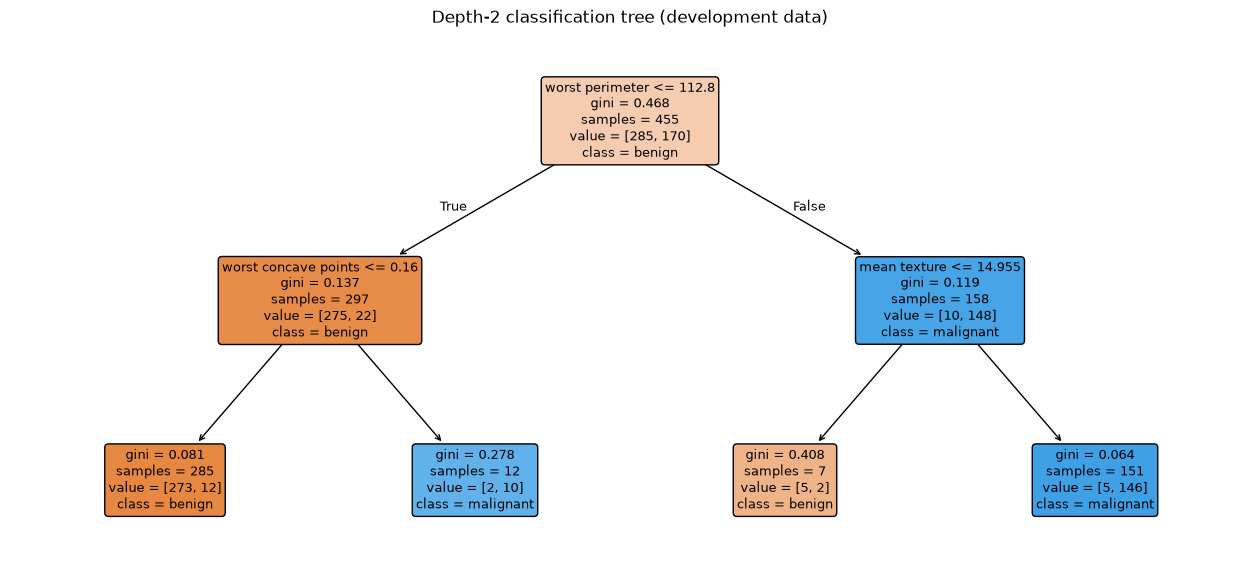

Root feature: worst perimeter
Root threshold: 112.79999923706055
First 5 predicted malignant probabilities: [0.96688742 0.04210526 0.04210526 0.96688742 0.96688742]


In [5]:
small_clf = DecisionTreeClassifier(max_depth=2, criterion='gini', random_state=SEED)
small_clf.fit(Xc_dev, yc_dev)
print(small_clf.classes_)
# print(data.target_names)

plt.figure(figsize=(16, 7))
plot_tree(small_clf, feature_names=list(Xc.columns), class_names=['benign', 'malignant'],
          filled=True, rounded=True, fontsize=9)
plt.title('Depth-2 classification tree (development data)')
plt.show()
print('Root feature:', Xc.columns[small_clf.tree_.feature[0]])
print('Root threshold:', small_clf.tree_.threshold[0])
print('First 5 predicted malignant probabilities:', small_clf.predict_proba(Xc_dev.iloc[:5])[:,1])

### B2. Visualize overfitting as tree depth increases

Compare **training** and **cross-validation** accuracy across tree depths. Unlike the held-out test set, the CV folds belong entirely to the development dataset.

**Questions:** At what depth does training accuracy become very high? Does validation performance continue improving? Why might the optimal depth vary with the data split?

[0.93406593 0.92582418 0.94230769 0.93131868 0.92582418]
[0.89010989 0.94505495 0.86813187 0.91208791 0.89010989]

[0.96153846 0.94230769 0.95604396 0.96153846 0.95879121]
[0.91208791 0.96703297 0.9010989  0.9010989  0.92307692]

[0.96428571 0.96703297 0.98076923 0.97252747 0.97527473]
[0.91208791 0.96703297 0.89010989 0.9010989  0.93406593]

[0.98626374 0.98076923 0.98901099 0.98626374 0.98626374]
[0.87912088 0.98901099 0.9010989  0.9010989  0.93406593]

[0.99725275 0.98626374 0.99175824 0.99175824 0.99175824]
[0.89010989 0.97802198 0.85714286 0.9010989  0.91208791]

[0.99725275 0.98901099 0.99725275 0.99450549 0.99725275]
[0.9010989  0.97802198 0.87912088 0.89010989 0.95604396]

[1.         0.99175824 1.         1.         1.        ]
[0.89010989 0.96703297 0.89010989 0.91208791 0.95604396]

[1.         0.99450549 1.         1.         1.        ]
[0.89010989 0.96703297 0.89010989 0.91208791 0.95604396]

[1. 1. 1. 1. 1.]
[0.89010989 0.96703297 0.89010989 0.91208791 0.95604396]

[1. 1

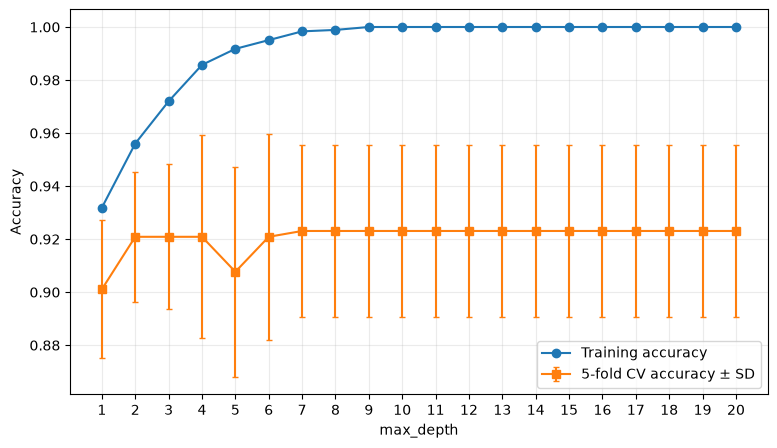

Best depth in this scan: 7


In [9]:
depths = list(range(1, 21))
cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
train_acc, cv_acc, cv_std = [], [], []
from sklearn.model_selection import cross_validate
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    result = cross_validate(model, Xc_dev, yc_dev, cv=cv_c, scoring='accuracy', return_train_score=True)

    print(result['train_score'])
    print(result['test_score'])
    print()

    train_acc.append(result['train_score'].mean())
    cv_acc.append(result['test_score'].mean())
    cv_std.append(result['test_score'].std())


plt.figure(figsize=(9, 5))
plt.plot(depths, train_acc, 'o-', label='Training accuracy')
plt.errorbar(depths, cv_acc, yerr=cv_std, fmt='s-', capsize=2, label='5-fold CV accuracy ± SD')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.xticks(depths)
plt.legend(); plt.grid(alpha=0.25); plt.show()
print('Best depth in this scan:', depths[int(np.argmax(cv_acc))])

### B3. Pre-pruning and post-pruning

Pre-pruning limits tree growth (e.g., `max_depth`, `min_samples_leaf`). Post-pruning grows a tree and removes subtrees according to the cost-complexity parameter `ccp_alpha`.

**Exercise:** Plot how increasing `ccp_alpha` changes the number of leaves and tree depth. Explain why the relationship is generally non-increasing.

[0.         0.00210989 0.00218001 0.00218264 0.0029304  0.00430549
 0.00431858 0.0043956  0.00527473 0.00586081 0.00627943 0.00730477
 0.00730484 0.01050899 0.01364431 0.03168777 0.33734531]



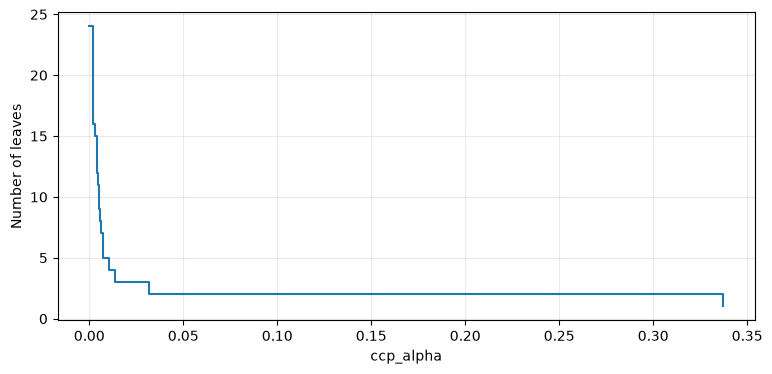

First/last alpha: 0.0 0.33734530771670845


In [10]:
base = DecisionTreeClassifier(random_state=SEED)
path = base.cost_complexity_pruning_path(Xc_dev, yc_dev)
alphas = np.unique(path.ccp_alphas)
print(alphas)
print()

pruned = [DecisionTreeClassifier(ccp_alpha=float(a), random_state=SEED).fit(Xc_dev, yc_dev)
          for a in alphas]
fig, ax = plt.subplots(figsize=(9, 4))
ax.step(alphas, [m.get_n_leaves() for m in pruned], where='post', label='Number of leaves')
ax.set_xlabel('ccp_alpha'); ax.set_ylabel('Number of leaves'); ax.grid(alpha=.25)
plt.show()
print('First/last alpha:', alphas[0], alphas[-1])

### B4. Hyperparameter selection using cross-validation

We compare **pre-pruning** (`max_depth`, `min_samples_leaf`) and **post-pruning** (`ccp_alpha`) candidates. The grid below is deliberately modest to keep the lab fast. Use balanced accuracy for selection; other metrics are also defensible when chosen in advance.

**Questions:** What does the best CV score estimate? Why must the held-out test set not be used to choose hyperparameters?

In [11]:
alpha_candidates = np.unique(np.quantile(alphas, [0, .25, .5, .75]))
param_grid_c = {
    'max_depth': [2, 4, 6, None],
    'min_samples_leaf': [1, 5, 10],
    'ccp_alpha': [float(a) for a in alpha_candidates],
}
search_c = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid_c,
                        cv=cv_c, scoring='balanced_accuracy', n_jobs=-1, refit=True)
search_c.fit(Xc_dev, yc_dev)
print('Best parameters:', search_c.best_params_)
print('Best mean CV balanced accuracy:', round(search_c.best_score_, 3))
print('Selected tree: depth=', search_c.best_estimator_.get_depth(),
      ', leaves=', search_c.best_estimator_.get_n_leaves())
# GridSearchCV(refit=True) already refits the selected tree on ALL development data.

Best parameters: {'ccp_alpha': 0.0, 'max_depth': 2, 'min_samples_leaf': 5}
Best mean CV balanced accuracy: 0.92
Selected tree: depth= 2 , leaves= 4


### B5. Final classification evaluation — held-out test set

**Only now** evaluate on the held-out test set. Compare against a majority-class baseline. Because malignant was recoded as class 1, `predict_proba(... )[:, 1]` gives the malignant probability.

**Questions:** Compare test and CV performance. Are they identical? Why not? Which errors (false negatives or false positives) might be especially consequential in a medical setting?

In [17]:
best_c = search_c.best_estimator_
print(best_c)
print()

baseline_c = DummyClassifier(strategy='most_frequent').fit(Xc_dev, yc_dev)

for name, model in [('Majority baseline', baseline_c), ('Tuned decision tree', best_c)]:
    pred = model.predict(Xc_test)
    print(name, '| accuracy:', round(accuracy_score(yc_test, pred), 3),
          '| balanced accuracy:', round(balanced_accuracy_score(yc_test, pred), 3))
print()

pred_c = best_c.predict(Xc_test)
prob_c = best_c.predict_proba(Xc_test)[:, 1]

print('ROC AUC:', round(roc_auc_score(yc_test, prob_c), 3))
print('Confusion matrix (rows=true, columns=predicted; 0=benign, 1=malignant):')
print(confusion_matrix(yc_test, pred_c, labels=[0, 1]))
print()

print(classification_report(yc_test, pred_c, target_names=['benign', 'malignant']))

DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, random_state=42)

Majority baseline | accuracy: 0.632 | balanced accuracy: 0.5
Tuned decision tree | accuracy: 0.921 | balanced accuracy: 0.898

ROC AUC: 0.919
Confusion matrix (rows=true, columns=predicted; 0=benign, 1=malignant):
[[71  1]
 [ 8 34]]

              precision    recall  f1-score   support

      benign       0.90      0.99      0.94        72
   malignant       0.97      0.81      0.88        42

    accuracy                           0.92       114
   macro avg       0.94      0.90      0.91       114
weighted avg       0.93      0.92      0.92       114



## Part C — Regression: Diabetes progression

The scikit-learn diabetes dataset contains 442 observations with 10 baseline clinical variables and a quantitative disease-progression measure one year later. The features in the scikit-learn loader are **already scaled**. Tree-based methods generally do not require standardization; do not mistake the loader's preprocessing for a requirement of regression trees.

The regression target is a study-specific quantitative outcome, **not a blood-glucose concentration or a diagnostic label**.

In [21]:
db = load_diabetes(as_frame=True)
Xr = db.data.copy()
yr = db.target.copy()
print('Features:', Xr.shape)
print()
print('Target summary:')
print(yr.describe())
print()

display(Xr.head())
Xr_dev, Xr_test, yr_dev, yr_test = train_test_split(
    Xr, yr, test_size=.20, random_state=SEED)
print('Development:', Xr_dev.shape, 'Held-out test:', Xr_test.shape)

Features: (442, 10)

Target summary:
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64



,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


Development: (353, 10) Held-out test: (89, 10)


### C1. Leaf predictions in a regression tree

Fit a depth-2 regression tree. Confirm that all development observations assigned to a given leaf receive the same prediction, equal to the **mean training target** in that leaf.

**Questions:** Why are regression tree predictions piecewise constant? Why can a deep regression tree fit the training data extremely closely?

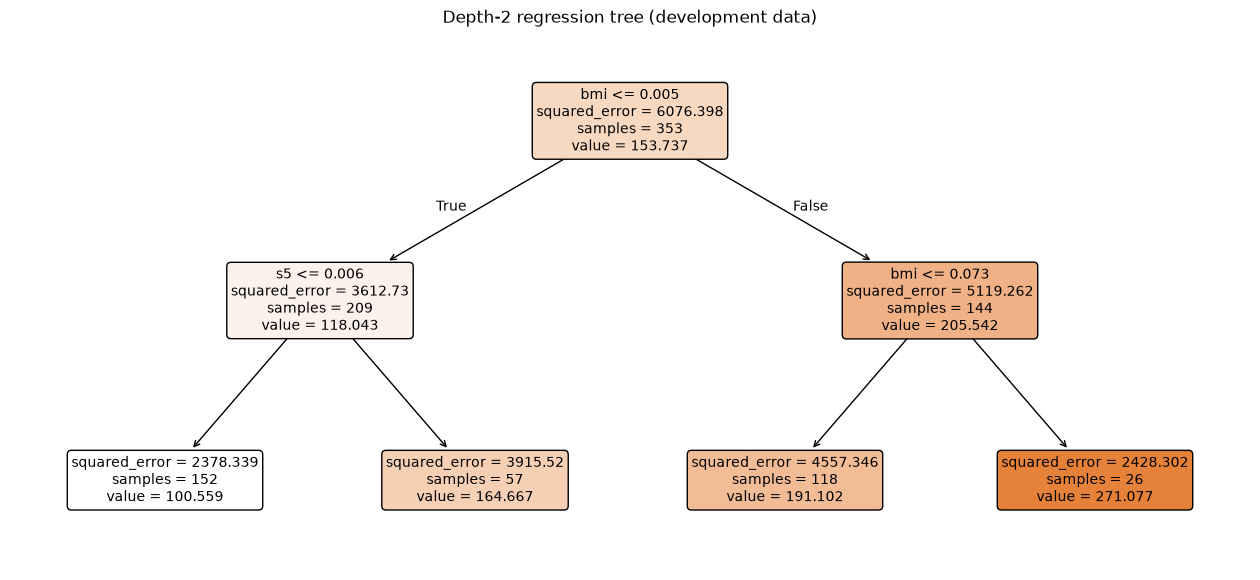

,n,mean_target,prediction
leaf,,,
2,152,100.559211,100.559211
3,57,164.666667,164.666667
5,118,191.101695,191.101695
6,26,271.076923,271.076923


In [13]:
small_reg = DecisionTreeRegressor(max_depth=2, criterion='squared_error', random_state=SEED)

small_reg.fit(Xr_dev, yr_dev)
plt.figure(figsize=(16, 7))
plot_tree(small_reg, feature_names=list(Xr.columns), filled=True, rounded=True, fontsize=10)
plt.title('Depth-2 regression tree (development data)'); plt.show()

leaf_ids = small_reg.apply(Xr_dev)
leaf_summary = pd.DataFrame({'leaf': leaf_ids, 'target': np.asarray(yr_dev),
                             'prediction': small_reg.predict(Xr_dev)})
summary = leaf_summary.groupby('leaf').agg(n=('target','size'), mean_target=('target','mean'),
                                           prediction=('prediction','first'))
display(summary)
assert np.allclose(summary['mean_target'], summary['prediction'])

### C2. Diagnose regression-tree overfitting

Plot training MSE and cross-validation MSE across depths. **Lower MSE is better**. Note that scikit-learn's `neg_mean_squared_error` scorer returns negative MSE because GridSearchCV always maximizes scores.

**Questions:** Why does training MSE generally decrease with increasing depth? Does CV MSE necessarily do the same?

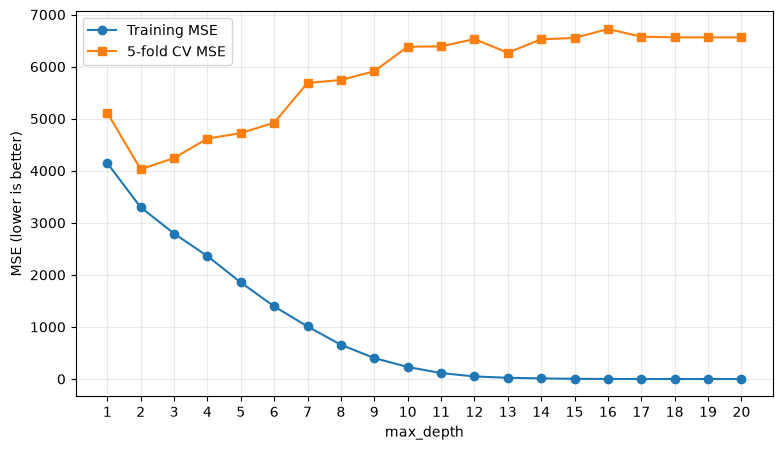

Lowest CV MSE depth in this scan: 2


In [22]:
cv_r = KFold(n_splits=5, shuffle=True, random_state=SEED)
train_mse, cv_mse = [], []
for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=SEED)
    scores = cross_validate(model, Xr_dev, yr_dev, cv=cv_r,
                            scoring='neg_mean_squared_error', return_train_score=True)
    train_mse.append(-scores['train_score'].mean())
    cv_mse.append(-scores['test_score'].mean())

plt.figure(figsize=(9, 5))
plt.plot(depths, train_mse, 'o-', label='Training MSE')
plt.plot(depths, cv_mse, 's-', label='5-fold CV MSE')
plt.xlabel('max_depth'); plt.ylabel('MSE (lower is better)'); plt.xticks(depths)
plt.legend(); plt.grid(alpha=.25); plt.show()
print('Lowest CV MSE depth in this scan:', depths[int(np.argmin(cv_mse))])

### C3. Cross-validation and regression-tree hyperparameters

Tune pre-pruning and post-pruning together on development data. The `ccp_alpha` scale is outcome-dependent; unlike classification, useful values may be much larger than 1. We generate candidate values from the **development-data pruning path**.

**Exercise:** Identify the selected parameters and explain why minimizing validation MSE may favor a relatively small tree.

In [15]:
rpath = DecisionTreeRegressor(random_state=SEED).cost_complexity_pruning_path(Xr_dev, yr_dev)
r_alphas = np.unique(np.quantile(rpath.ccp_alphas, [0, .25, .5, .75]))

param_grid_r = {'max_depth': [2, 4, 6, None],
                'min_samples_leaf': [1, 5, 10],
                'ccp_alpha': [float(a) for a in r_alphas]}
search_r = GridSearchCV(DecisionTreeRegressor(random_state=SEED), param_grid_r,
                        cv=cv_r, scoring='neg_mean_squared_error', n_jobs=-1, refit=True)
search_r.fit(Xr_dev, yr_dev)
print('Best parameters:', search_r.best_params_)
print('Best CV MSE:', round(-search_r.best_score_, 2))
print('Selected depth:', search_r.best_estimator_.get_depth(),
      '| leaves:', search_r.best_estimator_.get_n_leaves())

Best parameters: {'ccp_alpha': 0.0, 'max_depth': 2, 'min_samples_leaf': 1}
Best CV MSE: 4028.03
Selected depth: 2 | leaves: 4


### C4. Final regression evaluation — held-out test set

Compare the tuned tree against a baseline that always predicts the **mean development target**. Report MSE, MAE, and $R^2$. Plot predicted vs observed outcomes. Do not retune after seeing these results.

**Questions:** Does the tuned tree outperform the mean baseline? What does a negative $R^2$ mean? What does the predicted-vs-observed plot reveal about the limitations of piecewise-constant predictions?

Mean baseline: MSE=5361.53, MAE=64.01, R2=-0.012
Tuned regression tree: MSE=3735.50, MAE=49.37, R2=0.295


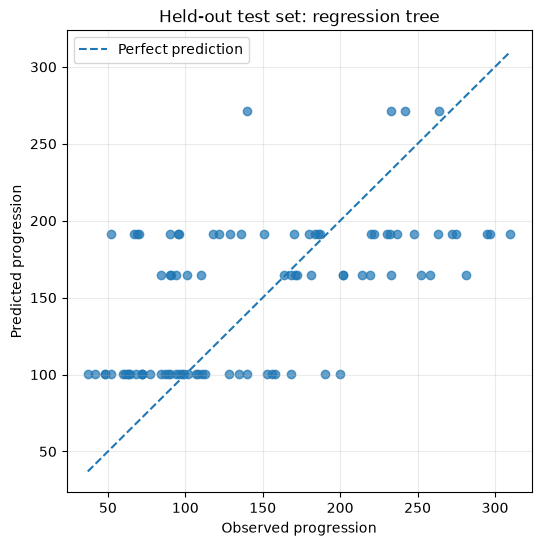

In [16]:
best_r = search_r.best_estimator_
baseline_r = DummyRegressor(strategy='mean').fit(Xr_dev, yr_dev)
for name, model in [('Mean baseline', baseline_r), ('Tuned regression tree', best_r)]:
    p = model.predict(Xr_test)
    print(f'{name}: MSE={mean_squared_error(yr_test, p):.2f}, '
          f'MAE={mean_absolute_error(yr_test, p):.2f}, R2={r2_score(yr_test, p):.3f}')
pred_r = best_r.predict(Xr_test)
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, pred_r, alpha=.7)
lo = min(np.min(yr_test), np.min(pred_r)); hi = max(np.max(yr_test), np.max(pred_r))
plt.plot([lo, hi], [lo, hi], '--', label='Perfect prediction')
plt.xlabel('Observed progression'); plt.ylabel('Predicted progression')
plt.title('Held-out test set: regression tree'); plt.legend(); plt.grid(alpha=.25)
plt.show()

## Part D — Synthesis and reflection

Write short answers (2–4 sentences each):

1. **Classification vs regression:** What differs in the target, node criterion, leaf prediction, and evaluation metric?
2. **Greedy splitting:** Why does the best local split not guarantee the globally optimal tree?
3. **Overfitting:** What evidence from the depth experiments indicates overfitting? Distinguish training from CV behavior.
4. **Pre-pruning vs post-pruning:** Give two pre-pruning hyperparameters and the post-pruning hyperparameter used in scikit-learn.
5. **Model selection:** Why is the held-out test set not involved in selecting tree depth or pruning strength?
6. **Biological interpretation:** Name one plausible limitation of applying the breast-cancer classifier or diabetes regressor to a new population.

### Optional extension (no further test-set tuning)
- Compare `criterion='gini'` and `criterion='entropy'` using cross-validation **on the classification development set only**.
- Compare `criterion='squared_error'` and `criterion='absolute_error'` for regression. Explain how the typical leaf prediction changes under absolute error.
- Use cross-validation to compare a tree with `max_depth=3` against an unrestricted tree, then explain the result without referring to the held-out test set.